# Лабораторная работа 1

1) Классификация данных методом k ближайших соседей ( kNN)

2) Классификация данных методом опорных векторов (SVM)

3) Построение softmax-классификатора

Вариант 1: задания 1 и 2 на наборе данных CIFAR-10

Вариант 2: задания 1 и 2 на наборе данных MNIST

Вариант 3: задания 1 и 3 на наборе данных CIFAR-10

Вариант 4: задания 1 и 3 на наборе данных MNIST

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере. 

## 1. Классификация данных методом k ближайших соседей ( kNN)

In [1]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 2.9 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/9.5 MB 3.2 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.5 MB 3.3 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 3.5 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 3.7 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 4.0 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.5 MB 4.3 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.5 MB 4.6 MB/s eta 0:00:01
   ------------------------------------ --- 8.7/9.5 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 4.9 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? 


[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scripts.data_utils import load_CIFAR10


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST 
sklearn.datasets import load_digits
digits = load_digits()

In [25]:
import os
import urllib.request
import tarfile

url = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"

archive_path = "cifar-10-python.tar.gz"

extract_path = "scripts/datasets"

os.makedirs(extract_path, exist_ok=True)

print("Скачивание CIFAR-10...")

urllib.request.urlretrieve(
    url,
    archive_path
)

print("Скачивание завершено.")

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(extract_path)

print("Распаковка завершена.")

# Удаляем архив
os.remove(archive_path)

Скачивание CIFAR-10...
Скачивание завершено.
Распаковка завершена.


In [26]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Clear previously loaded data.
Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



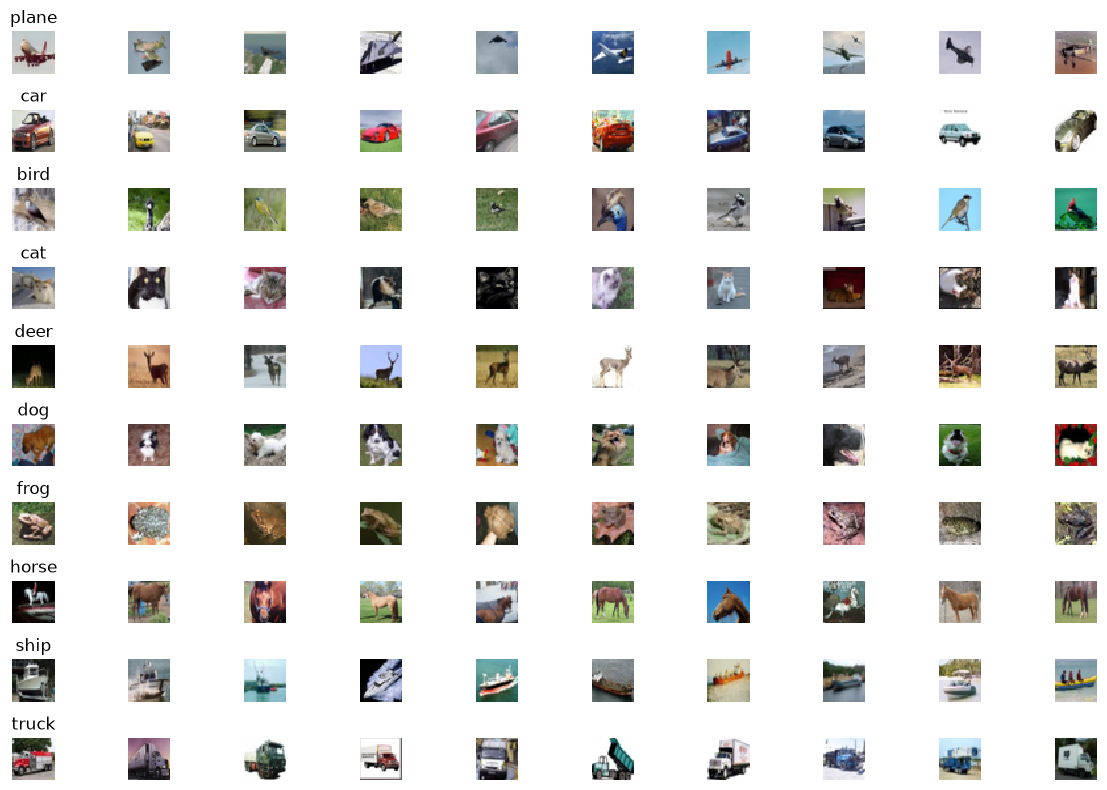

In [27]:
classes = [
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(12, 8))

for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, 10, replace=False)

    for i, idx in enumerate(idxs):
        plt_idx = y * 10 + i + 1

        plt.subplot(10, 10, plt_idx)
        plt.imshow(X_train[idx].astype(np.uint8))
        plt.axis('off')

        if i == 0:
            plt.title(cls)

plt.tight_layout()
plt.show()

1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив. 

In [ ]:
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print('Training data shape: ', X_train.shape)
print('Test data shape: ', X_test.shape)

Training data shape:  (50000, 3072)
Test data shape:  (10000, 3072)


1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке. 

In [29]:
from scripts.classifiers.k_nearest_neighbor import KNearestNeighbor

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

1.5 Выполните классификацию на тестовой выборке

In [30]:
num_test = X_test.shape[0]
batch_size = 100

y_test_pred = np.zeros(num_test)

for start in range(0, num_test, batch_size):
    end = min(start + batch_size, num_test)

    print(f"Обработка {start} - {end} из {num_test}")

    y_test_pred[start:end] = classifier.predict(
        X_test[start:end],
        k=1,
        num_loops=0
    )

Обработка 0 - 100 из 10000
Обработка 100 - 200 из 10000
Обработка 200 - 300 из 10000
Обработка 300 - 400 из 10000
Обработка 400 - 500 из 10000
Обработка 500 - 600 из 10000
Обработка 600 - 700 из 10000
Обработка 700 - 800 из 10000
Обработка 800 - 900 из 10000
Обработка 900 - 1000 из 10000
Обработка 1000 - 1100 из 10000
Обработка 1100 - 1200 из 10000
Обработка 1200 - 1300 из 10000
Обработка 1300 - 1400 из 10000
Обработка 1400 - 1500 из 10000
Обработка 1500 - 1600 из 10000
Обработка 1600 - 1700 из 10000
Обработка 1700 - 1800 из 10000
Обработка 1800 - 1900 из 10000
Обработка 1900 - 2000 из 10000
Обработка 2000 - 2100 из 10000
Обработка 2100 - 2200 из 10000
Обработка 2200 - 2300 из 10000
Обработка 2300 - 2400 из 10000
Обработка 2400 - 2500 из 10000
Обработка 2500 - 2600 из 10000
Обработка 2600 - 2700 из 10000
Обработка 2700 - 2800 из 10000
Обработка 2800 - 2900 из 10000
Обработка 2900 - 3000 из 10000
Обработка 3000 - 3100 из 10000
Обработка 3100 - 3200 из 10000
Обработка 3200 - 3300 из 1000

1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки. 


(100, 100)


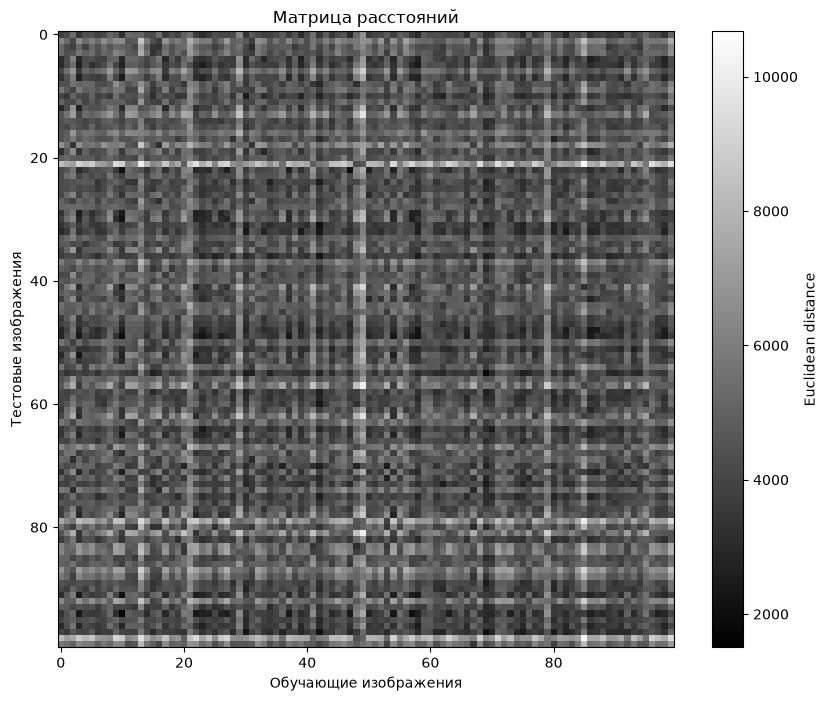

In [31]:
X_test_small = X_test[:100]
X_train_small = X_train[:100]

dists = classifier.compute_distances_no_loops(X_test_small)

dists = dists[:, :100]

print(dists.shape)

plt.figure(figsize=(10, 8))

plt.imshow(dists, interpolation='nearest', cmap='gray')
plt.colorbar(label='Euclidean distance')

plt.xlabel('Обучающие изображения')
plt.ylabel('Тестовые изображения')
plt.title('Матрица расстояний')

plt.show()


1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [32]:
accuracy = np.mean(y_test_pred == y_test)

print(f"Доля правильно классифицированных изображений: {accuracy:.4f}")
print(f"Точность классификации: {accuracy * 100:.2f}%")

Доля правильно классифицированных изображений: 0.3539
Точность классификации: 35.39%


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

In [33]:
k_values = [1, 3, 5, 7, 9]
accuracies = []

X_test_small = X_test[:5000]
y_test_small = y_test[:5000]

dists = classifier.compute_distances_no_loops(X_test_small)

for k in k_values:
    y_pred_k = classifier.predict_labels(dists, k=k)

    accuracy_k = np.mean(y_pred_k == y_test_small)
    accuracies.append(accuracy_k)

    print(f"k = {k}: accuracy = {accuracy_k:.4f}")


k = 1: accuracy = 0.3532
k = 3: accuracy = 0.3352
k = 5: accuracy = 0.3390
k = 7: accuracy = 0.3380
k = 9: accuracy = 0.3424


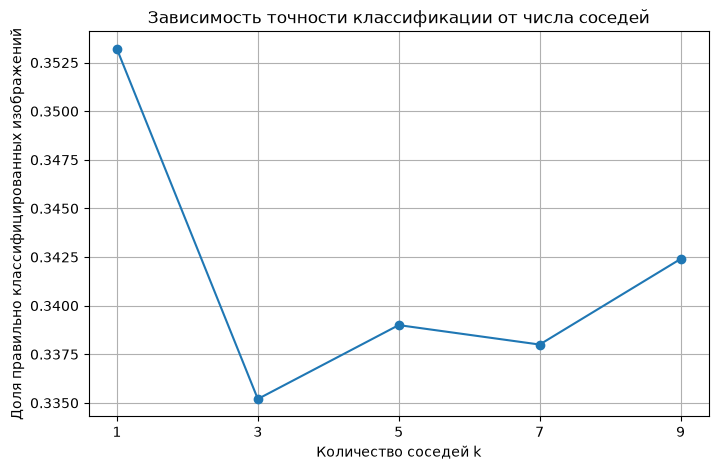

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker='o')

plt.xlabel('Количество соседей k')
plt.ylabel('Доля правильно классифицированных изображений')
plt.title('Зависимость точности классификации от числа соседей')
plt.xticks(k_values)
plt.grid(True)

plt.show()

1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


In [35]:
from sklearn.model_selection import KFold

k_values = [1, 3, 5, 7, 9]

num_train_cv = 5000

X_cv = X_train[:num_train_cv]
y_cv = y_train[:num_train_cv]

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

for k in k_values:
    fold_accuracies = []

    print(f"\nk = {k}")

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_cv), 1):
        X_train_fold = X_cv[train_idx]
        y_train_fold = y_cv[train_idx]

        X_val_fold = X_cv[val_idx]
        y_val_fold = y_cv[val_idx]

        classifier_cv = KNearestNeighbor()
        classifier_cv.train(X_train_fold, y_train_fold)

        # Расстояния считаем один раз для текущего fold
        dists = classifier_cv.compute_distances_no_loops(X_val_fold)

        y_pred = classifier_cv.predict_labels(dists, k=k)

        accuracy = np.mean(y_pred == y_val_fold)
        fold_accuracies.append(accuracy)

        print(f"  Fold {fold}: {accuracy:.4f}")

    cv_results[k] = fold_accuracies


k = 1
  Fold 1: 0.2910
  Fold 2: 0.2630
  Fold 3: 0.2680
  Fold 4: 0.2590
  Fold 5: 0.2760

k = 3
  Fold 1: 0.2790
  Fold 2: 0.2600
  Fold 3: 0.2480
  Fold 4: 0.2370
  Fold 5: 0.2650

k = 5
  Fold 1: 0.2870
  Fold 2: 0.2600
  Fold 3: 0.2610
  Fold 4: 0.2650
  Fold 5: 0.2740

k = 7
  Fold 1: 0.2910
  Fold 2: 0.2720
  Fold 3: 0.2720
  Fold 4: 0.2620
  Fold 5: 0.2750

k = 9
  Fold 1: 0.2810
  Fold 2: 0.2710
  Fold 3: 0.2890
  Fold 4: 0.2610
  Fold 5: 0.2800


In [36]:
mean_accuracies = {}

for k in k_values:
    mean_accuracy = np.mean(cv_results[k])
    mean_accuracies[k] = mean_accuracy

    print(f"k = {k}: средняя accuracy = {mean_accuracy:.4f}")

k = 1: средняя accuracy = 0.2714
k = 3: средняя accuracy = 0.2578
k = 5: средняя accuracy = 0.2694
k = 7: средняя accuracy = 0.2744
k = 9: средняя accuracy = 0.2764


In [37]:
best_k = max(mean_accuracies, key=mean_accuracies.get)

print(f"\nЛучшее значение k: {best_k}")
print(f"Средняя accuracy: {mean_accuracies[best_k]:.4f}")


Лучшее значение k: 9
Средняя accuracy: 0.2764


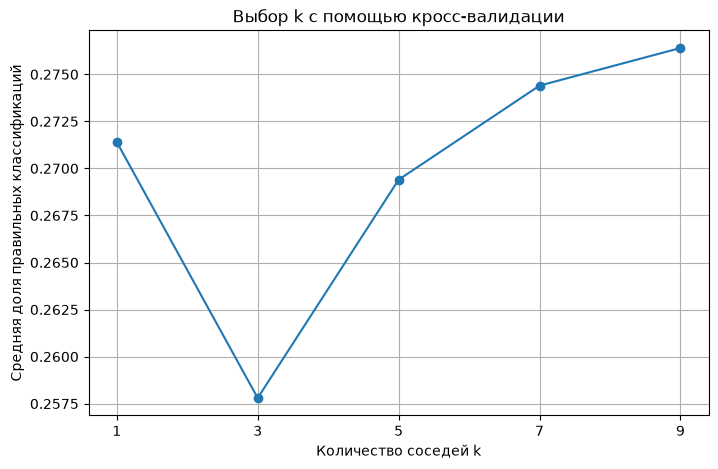

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(mean_accuracies.keys()),
    list(mean_accuracies.values()),
    marker='o'
)

plt.xlabel('Количество соседей k')
plt.ylabel('Средняя доля правильных классификаций')
plt.title('Выбор k с помощью кросс-валидации')
plt.xticks(k_values)
plt.grid(True)

plt.show()


1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [39]:
best_k = 9

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

In [40]:
num_test = X_test.shape[0]
batch_size = 100

y_test_pred_best = np.zeros(num_test, dtype=int)

for start in range(0, num_test, batch_size):
    end = min(start + batch_size, num_test)

    print(f"Обработка {start} - {end} из {num_test}")

    dists = classifier.compute_distances_no_loops(
        X_test[start:end]
    )

    y_test_pred_best[start:end] = classifier.predict_labels(
        dists,
        k=best_k
    )

Обработка 0 - 100 из 10000
Обработка 100 - 200 из 10000
Обработка 200 - 300 из 10000
Обработка 300 - 400 из 10000
Обработка 400 - 500 из 10000
Обработка 500 - 600 из 10000
Обработка 600 - 700 из 10000
Обработка 700 - 800 из 10000
Обработка 800 - 900 из 10000
Обработка 900 - 1000 из 10000
Обработка 1000 - 1100 из 10000
Обработка 1100 - 1200 из 10000
Обработка 1200 - 1300 из 10000
Обработка 1300 - 1400 из 10000
Обработка 1400 - 1500 из 10000
Обработка 1500 - 1600 из 10000
Обработка 1600 - 1700 из 10000
Обработка 1700 - 1800 из 10000
Обработка 1800 - 1900 из 10000
Обработка 1900 - 2000 из 10000
Обработка 2000 - 2100 из 10000
Обработка 2100 - 2200 из 10000
Обработка 2200 - 2300 из 10000
Обработка 2300 - 2400 из 10000
Обработка 2400 - 2500 из 10000
Обработка 2500 - 2600 из 10000
Обработка 2600 - 2700 из 10000
Обработка 2700 - 2800 из 10000
Обработка 2800 - 2900 из 10000
Обработка 2900 - 3000 из 10000
Обработка 3000 - 3100 из 10000
Обработка 3100 - 3200 из 10000
Обработка 3200 - 3300 из 1000

In [42]:
accuracy_best = np.mean(y_test_pred_best == y_test)

print(f"Доля правильно классифицированных изображений: {accuracy_best:.4f}")
print(f"Точность классификации: {accuracy_best * 100:.2f}%")

Доля правильно классифицированных изображений: 0.3398
Точность классификации: 33.98%


1.11 Сделайте выводы по результатам 1 части задания.

In [ ]:
по результатам кросс-валидации было выбрано 9 ближайших соседей, но на тесте он показал худший результат чем при k=1. 

## 2.  Классификация данных методом опорных векторов (SVM)

2.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

2.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

2.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву дынных и заполните ее 1.

In [ ]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) 
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) 
plt.show()


X_train -= mean_image
X_val -= mean_image
X_test -= mean_image



X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])


print(X_train.shape, X_val.shape, X_test.shape)

2.4 Реализуйте loss-функции в scripts/classifiers/linear_svm.py



In [ ]:

from scripts.classifiers.linear_svm import svm_loss_naive
import time


W = np.random.randn(3073, 10) * 0.0001 

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % (loss, ))


2.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [ ]:

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.0)

from scripts.gradient_check import grad_check_sparse
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)


loss, grad = svm_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

2.6 Сравните svm_loss_naive и svm_loss_vectorized реализации

In [ ]:
tic = time.time()
_, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = svm_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

2.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

In [ ]:
from scripts.classifiers import LinearSVM
svm = LinearSVM()
tic = time.time()
loss_hist = svm.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

In [ ]:
y_train_pred = svm.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

2.8 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [ ]:
learning_rates = [1e-7, 5e-5]
regularization_strengths = [2.5e4, 5e4]

2.9 Сделайте выводы по второй части задания

## 3.  Построение softmax-классификатора

3.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [1]:
from scripts.data_utils import load_CIFAR10
import numpy as np
import matplotlib.pyplot as plt

cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print('Training data shape: ', X_train.shape)
print('Test data shape: ', X_test.shape)

# 3.1 Разделяем train на train и validation
X_val = X_train[:1000]
y_val = y_train[:1000]

X_train = X_train[1000:]
y_train = y_train[1000:]

print('Training data shape:', X_train.shape)
print('Validation data shape:', X_val.shape)
print('Test data shape:', X_test.shape)


Training data shape:  (50000, 3072)
Test data shape:  (10000, 3072)
Training data shape: (49000, 3072)
Validation data shape: (1000, 3072)
Test data shape: (10000, 3072)


3.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

3.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву данных и заполните ее единицами.

[130.6544898  136.00577551 132.51434694 130.08681633 135.38777551
 131.80189796 130.99630612 136.18583673 132.52006122 131.5157551 ]


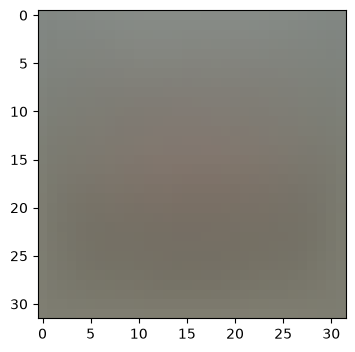

In [2]:
mean_image = np.mean(X_train, axis=0)

print(mean_image[:10])

# Визуализируем среднее изображение
plt.figure(figsize=(4, 4))
plt.imshow(mean_image.reshape(32, 32, 3).astype('uint8'))
plt.show()

# Вычитаем среднее
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

In [3]:
X_train = np.hstack([
    X_train,
    np.ones((X_train.shape[0], 1))
])

X_val = np.hstack([
    X_val,
    np.ones((X_val.shape[0], 1))
])

X_test = np.hstack([
    X_test,
    np.ones((X_test.shape[0], 1))
])

print(X_train.shape, X_val.shape, X_test.shape)

(49000, 3073) (1000, 3073) (10000, 3073)


3.4 Реализуйте функции в classifiers/softmax.py




In [4]:
X_dev = X_train[:500]
y_dev = y_train[:500]

In [5]:
from scripts.classifiers.softmax import softmax_loss_naive
import time

# Generate a random softmax weight matrix and use it to compute the loss.
W = np.random.randn(3073, 10) * 0.0001
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# As a rough sanity check, our loss should be something close to -log(0.1).
print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.284993
sanity check: 2.302585


3.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [6]:
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)


from scripts.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)


loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)

numerical: -1.574497 analytic: -1.574497, relative error: 6.891295e-09
numerical: 0.321808 analytic: 0.321808, relative error: 1.217124e-07
numerical: 0.509555 analytic: 0.509555, relative error: 5.578602e-08
numerical: 2.354976 analytic: 2.354976, relative error: 2.066820e-08
numerical: -0.464304 analytic: -0.464304, relative error: 2.681396e-08
numerical: -2.300712 analytic: -2.300712, relative error: 3.426243e-09
numerical: -5.025646 analytic: -5.025646, relative error: 2.547574e-08
numerical: 0.204052 analytic: 0.204052, relative error: 4.234136e-08
numerical: 1.187452 analytic: 1.187452, relative error: 1.441073e-08
numerical: -0.689030 analytic: -0.689030, relative error: 1.013359e-08
numerical: -0.154019 analytic: -0.154019, relative error: 1.183977e-07
numerical: 1.551803 analytic: 1.551803, relative error: 9.534216e-09
numerical: 1.159772 analytic: 1.159772, relative error: 1.919106e-08
numerical: 1.267016 analytic: 1.267016, relative error: 8.067688e-09
numerical: 0.130458 an

3.6 Сравните softmax_loss_naive и softmax_loss_vectorized реализации

In [7]:
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from scripts.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))


grad_difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('Loss difference: %f' % np.abs(loss_naive - loss_vectorized))
print('Gradient difference: %f' % grad_difference)

naive loss: 2.284993e+00 computed in 0.046960s
vectorized loss: 2.284993e+00 computed in 0.004983s
Loss difference: 0.000000
Gradient difference: 0.000000


3.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

3.8 Обучите Softmax-классификатор и оцените accuracy на тестовой выборке.

In [ ]:
from scripts.classifiers.linear_classifier import Softmax

classifier = Softmax()

loss_history = classifier.train(X_train, y_train)

y_train_pred = classifier.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred),))

3.9 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [15]:
learning_rates = [1e-7, 5e-5]
regularization_strengths = [2.5e4, 5e4]

results = {}

best_val = -1
best_softmax = None
best_lr = None
best_reg = None

for lr in learning_rates:
    for reg in regularization_strengths:

        classifier = Softmax()

        loss_history = classifier.train(
            X_train,
            y_train,
            learning_rate=lr,
            reg=reg,
            num_iters=1500,
            batch_size=200,
            verbose=False
        )

        y_train_pred = classifier.predict(X_train)
        train_accuracy = np.mean(y_train == y_train_pred)

        y_val_pred = classifier.predict(X_val)
        val_accuracy = np.mean(y_val == y_val_pred)

        results[(lr, reg)] = (train_accuracy, val_accuracy)

        print(
            'lr = %e, reg = %e, train accuracy = %f, val accuracy = %f'
            % (lr, reg, train_accuracy, val_accuracy)
        )

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = classifier
            best_lr = lr
            best_reg = reg

lr = 1.000000e-07, reg = 2.500000e+04, train accuracy = 0.324592, val accuracy = 0.334000
lr = 1.000000e-07, reg = 5.000000e+04, train accuracy = 0.311612, val accuracy = 0.321000


c:\Users\vliva\Desktop\lr1\scripts\classifiers\softmax.py:87: RuntimeWarning: overflow encountered in scalar multiply
  loss += reg * np.sum(W * W)
c:\Users\vliva\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
c:\Users\vliva\Desktop\lr1\scripts\classifiers\softmax.py:87: RuntimeWarning: overflow encountered in multiply
  loss += reg * np.sum(W * W)


lr = 5.000000e-05, reg = 2.500000e+04, train accuracy = 0.105429, val accuracy = 0.108000


c:\Users\vliva\Desktop\lr1\scripts\classifiers\softmax.py:88: RuntimeWarning: overflow encountered in multiply
  dW += 2 * reg * W
c:\Users\vliva\Desktop\lr1\scripts\classifiers\softmax.py:58: RuntimeWarning: invalid value encountered in dot
  scores = X.dot(W)


lr = 5.000000e-05, reg = 5.000000e+04, train accuracy = 0.099959, val accuracy = 0.102000


In [16]:
print()
print('Best validation accuracy:', best_val)
print('Best learning rate:', best_lr)
print('Best regularization strength:', best_reg)

y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)

print('Test accuracy:', test_accuracy)


Best validation accuracy: 0.334
Best learning rate: 1e-07
Best regularization strength: 25000.0
Test accuracy: 0.3268


3.10 Сделайте выводы по третьей части задания

In [ ]:
Наилучший результат показали learning_rate = 1e-7 и regularization_strength = 2.5e4. Точность на валидационной выборке - 33,4%.
Точность на тестовой выборке - 32,68%.